# Barrido de K con FedAvg

Analiza el barrido K ∈ {5, 10, 15, 20, 25, 30} × 3 semillas de FedAvg (la replica de Li et al., 2022) y lo compara con Greedy, la referencia sin aprendizaje que tambien usa el paper. Ademas de las metricas del paper, muestra lo que solo tienen los metodos que aprenden y comparten: curvas de aprendizaje, episodios hasta converger, comunicacion, dispersion de pesos y perdida.

**Datos.** En Hypatia, desde la raiz del repo: `make run-fedavg` (18 trabajos de GPU) y, para la referencia, `make run-greedy`. Cuando terminen (`make sq` vacio), en la maquina local: `make pull-runs`. Si todavia no hay corridas de Greedy, todo funciona igual con FedAvg solo.

**Como se resume cada numero** (las mismas reglas que el resto de la tesis):
- valor de una corrida = promedio del ultimo 10 % de sus episodios;
- puntos y barras = media ± 1 desviacion entre las 3 semillas;
- las metricas por par (outage, delay, potencia, vecinos, perdida) se promedian primero sobre los K agentes.

In [ ]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "..")  # v2v/, para importar analysis.py y plots.py
from analysis import (
    convergence_episode,
    final_values,
    load_metadata,
    load_runs,
    per_episode_means,
    summarize_by_k,
)
from plots import (
    EXPECTED_KS,
    EXPECTED_SEEDS,
    LABELS,
    LI_FIG3_MBPS,
    METHODS,
    PERCENT,
    REFERENCE,
    TEXT,
    TEXT_2,
    fedavg_models_per_episode,
    gossip_models_per_episode,
    k_colors,
    log_y,
    method_label,
    plot_vs_k,
    use_thesis_style,
)

RUNS_ROOT = Path(os.environ.get("V2V_RUNS_ROOT", "../runs"))
FIG_DIR = Path(os.environ.get("V2V_FIG_DIR", "../runs/figures"))
FIG_DIR.mkdir(parents=True, exist_ok=True)

METHODS_TO_SHOW = [
    "fedavg",
    "greedy",
]  # agrega "dte" y "gossip" cuando existan sus corridas
WINDOW = 50  # episodios de la media movil y de la convergencia
FINAL_FRACTION = 0.1  # tramo final: el ultimo 10 % de los episodios
use_thesis_style()

## Carga y cobertura

Una fila por metodo y K, una columna por semilla: cada celda dice cuantos episodios tiene esa corrida. Todas deberian tener los mismos; una celda vacia es una corrida que falta o que fallo.

In [ ]:
runs = load_runs(RUNS_ROOT, methods=METHODS_TO_SHOW)
if "comm_bytes" in runs:
    runs["comm_mb"] = runs["comm_bytes"] / 1e6

per_episode = per_episode_means(runs)
for metric in PERCENT:
    if metric in per_episode:
        per_episode[metric] *= 100

methods = [m for m in METHODS if m in set(per_episode["method"])]
learners = [
    m
    for m in methods
    if "train_loss" in per_episode
    and per_episode.loc[per_episode["method"] == m, "train_loss"].notna().any()
]
ks = sorted(per_episode["k"].unique())

final = final_values(per_episode, FINAL_FRACTION)
if learners:  # una convergencia por corrida, sobre su curva completa de recompensa
    final["convergence_episode"] = (
        per_episode[per_episode["method"].isin(learners)]
        .sort_values("episode")
        .groupby(["method", "k", "seed"])["reward"]
        .apply(lambda rewards: convergence_episode(rewards.to_numpy(), window=WINDOW))
    )
summary = summarize_by_k(final)

coverage = per_episode.pivot_table(
    index=["method", "k"], columns="seed", values="episode", aggfunc="count"
)
coverage = coverage.reindex(
    pd.MultiIndex.from_product([methods, EXPECTED_KS], names=["method", "k"])
).reindex(columns=EXPECTED_SEEDS)
missing = int(coverage.isna().to_numpy().sum())
if missing or coverage.stack().nunique() > 1:
    print(
        f"Atencion: faltan {missing} corridas o no todas tienen el mismo numero de episodios."
    )
coverage.rename(index=method_label, level="method")

seed          0     1     2
method k                   
FedAvg 5   4000  4000  4000
       10  4000  4000  4000
       15  4000  4000  4000
       20  4000  4000  4000
       25  4000  4000  4000
       30  4000  4000  4000
Greedy 5   4000  4000  4000
       10  4000  4000  4000
       15  4000  4000  4000
       20  4000  4000  4000
       25  4000  4000  4000
       30  4000  4000  4000

## Curvas de aprendizaje

Recompensa por episodio (media movil de `WINDOW` episodios), una grafica por K: la linea es la media entre semillas y la banda, ±1 desviacion. Greedy es la referencia plana. Lo que hay que ver: que la curva de FedAvg suba, se estabilice y quede por encima de Greedy.

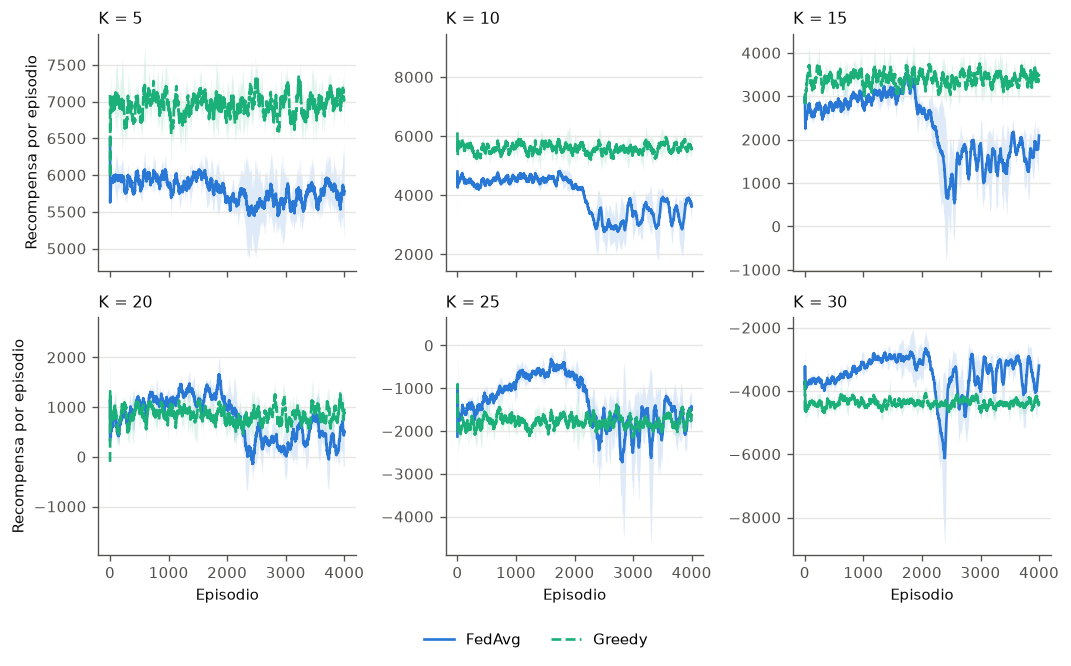

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(9.0, 5.2), sharex=True)
for ax, k in zip(axes.flat, EXPECTED_KS):
    for method in methods:
        run = per_episode[
            (per_episode["method"] == method) & (per_episode["k"] == k)
        ].sort_values("episode")
        if run.empty:
            continue
        smooth = run.groupby("seed")["reward"].transform(
            lambda s: s.rolling(WINDOW, min_periods=1).mean()
        )
        stats = smooth.groupby(run["episode"]).agg(["mean", "std"]).fillna(0.0)
        style = METHODS[method]
        ax.fill_between(
            stats.index,
            stats["mean"] - stats["std"],
            stats["mean"] + stats["std"],
            color=style["color"],
            alpha=0.15,
            linewidth=0,
        )
        ax.plot(
            stats.index,
            stats["mean"],
            color=style["color"],
            linestyle=style["linestyle"],
            label=style["label"],
        )
    ax.set_title(f"K = {k}")
for ax in axes[-1]:
    ax.set_xlabel("Episodio")
for ax in axes[:, 0]:
    ax.set_ylabel(LABELS["reward"])
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.tight_layout()
fig.legend(
    handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=len(methods)
)
fig.savefig(FIG_DIR / "barrido_curvas_aprendizaje_fedavg.pdf")
plt.show()

## Episodios hasta converger vs. K

Primer episodio desde el cual la media movil de `WINDOW` episodios de la recompensa queda dentro de ±5 % de su valor final (`analysis.convergence_episode`). Li et al. afirman que con mas agentes hacen falta mas iteraciones para estabilizar la recompensa (Sec. V-G), pero no lo grafican para varios K: esta figura lo pone a prueba.

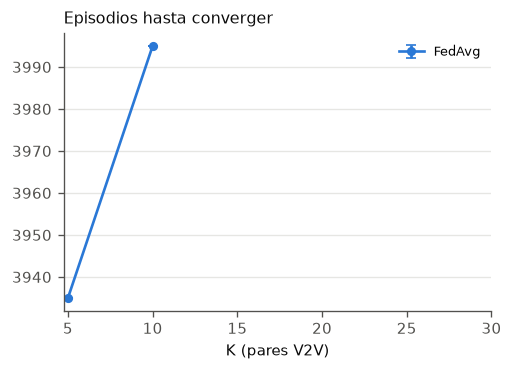

seed            0       2
method k                 
FedAvg 5   3935.0     NaN
       10     NaN  3995.0

In [ ]:
converged = (
    final["convergence_episode"].dropna()
    if "convergence_episode" in final
    else pd.Series(dtype=float)
)
if not learners:
    print("Ningun metodo de los cargados aprende.")
elif converged.empty:
    print(
        f"Ninguna corrida se estabiliza dentro de ±5 % con una ventana de {WINDOW} episodios (o tienen menos episodios que la ventana)."
    )
else:
    fig, ax = plt.subplots(figsize=(4.6, 3.0))
    plot_vs_k(ax, summary, "convergence_episode", learners)
    ax.legend(fontsize=7.5)
    plt.show()
    display(converged.unstack("seed").rename(index=method_label, level="method"))

## Metricas del paper vs. K

Las cuatro metricas de desempeño de la tesis. En la tasa CUE, las cruces grises son los valores de Li et al. (2022), Fig. 3, leidos de la figura: sirven para comparar la **tendencia** (cuanto cae la tasa al pasar de 5 a 30 pares), no el valor exacto, porque el entorno esta simplificado. El delay no se compara con el paper (la Fig. 8 mide otra cosa) y la recompensa esta normalizada, asi que su escala es propia.

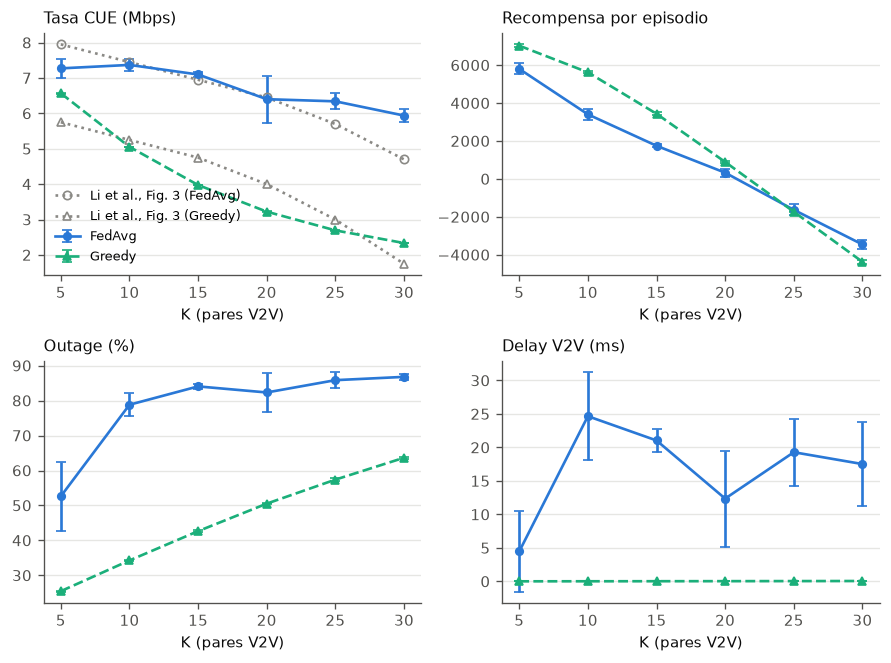

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(7.5, 5.6))
for ax, metric in zip(
    axes.flat, ["cue_rate_mbps", "reward", "outage_rate", "v2v_delay_ms"]
):
    plot_vs_k(ax, summary, metric, methods)
for method in methods:
    if method in LI_FIG3_MBPS:
        ref = LI_FIG3_MBPS[method]
        axes[0][0].plot(
            list(ref),
            list(ref.values()),
            color=REFERENCE,
            linestyle=":",
            marker=METHODS[method]["marker"],
            fillstyle="none",
            markersize=5,
            label=f"Li et al., Fig. 3 ({method_label(method)})",
        )
axes[0][0].legend(fontsize=7.5)
fig.tight_layout()
fig.savefig(FIG_DIR / f"barrido_desempeno_{'_'.join(methods)}.pdf")
plt.show()

## FedAvg frente a Greedy, semilla por semilla

Con la misma semilla los dos metodos ven exactamente las mismas posiciones, asi que se comparan corrida contra corrida. Es la tarea 1.6 extendida a todos los K: si FedAvg no le gana a Greedy, hay que revisar antes de seguir con el gossip.

In [ ]:
A, B = "fedavg", "greedy"
if {A, B} <= set(methods):
    pairs = final[["cue_rate_mbps", "reward"]].unstack("method").dropna()
    rows = []
    for k in sorted(pairs.index.get_level_values("k").unique()):
        sub = pairs.xs(k, level="k")
        for metric in ["cue_rate_mbps", "reward"]:
            diff = sub[(metric, A)] - sub[(metric, B)]
            rows.append(
                {
                    "K": k,
                    "Metrica": LABELS[metric],
                    f"{method_label(A)} - {method_label(B)}": diff.mean(),
                    "Diferencia (%)": 100 * diff.mean() / abs(sub[(metric, B)].mean()),
                    f"Semillas en que gana {method_label(A)}": f"{int((diff > 0).sum())} de {len(diff)}",
                }
            )
    display(pd.DataFrame(rows).set_index(["K", "Metrica"]).round(2))
else:
    print(
        f"Faltan corridas de {method_label(A)} o de {method_label(B)} para compararlas."
    )

FedAvg - Greedy  Diferencia (%)  \
K  Metrica                                                    
5  Tasa CUE (Mbps)                     0.70           10.71   
   Recompensa por episodio         -1224.66          -17.42   
10 Tasa CUE (Mbps)                     2.32           45.82   
   Recompensa por episodio         -2216.88          -39.42   
15 Tasa CUE (Mbps)                     3.12           78.59   
   Recompensa por episodio         -1688.19          -49.12   
20 Tasa CUE (Mbps)                     3.18           98.61   
   Recompensa por episodio          -565.70          -63.19   
25 Tasa CUE (Mbps)                     3.65          135.38   
   Recompensa por episodio           102.47            5.92   
30 Tasa CUE (Mbps)                     3.60          154.23   
   Recompensa por episodio           915.66           20.95   

                           Semillas en que gana FedAvg  
K  Metrica                                              
5  Tasa CUE (Mbps)                              3 de 3  
   Recompensa por episodio                      0 de 3  
10 Tasa CUE (Mbps)                              3 de 3  
   Recompensa por episodio                      0 de 3  
15 Tasa CUE (Mbps)                              3 de 3  
   Recompensa por episodio                      0 de 3  
20 Tasa CUE (Mbps)                              3 de 3  
   Recompensa por episodio                      0 de 3  
25 Tasa CUE (Mbps)                              3 de 3  
   Recompensa por episodio                      2 de 3  
30 Tasa CUE (Mbps)                              3 de 3  
   Recompensa por episodio                      3 de 3

## Comunicacion vs. K

Modelos transmitidos por episodio, en cantidad y en MB, y la carga del nodo mas cargado. En FedAvg cada ronda mueve 2K modelos (K subidas y K bajadas) y la torre participa en todas, asi que con rondas cada 50 de los 200 slots deben salir exactamente 8K por episodio (la linea gris), y la carga maxima es igual al total.

No transmiten modelos (0 en todos los K): Greedy.


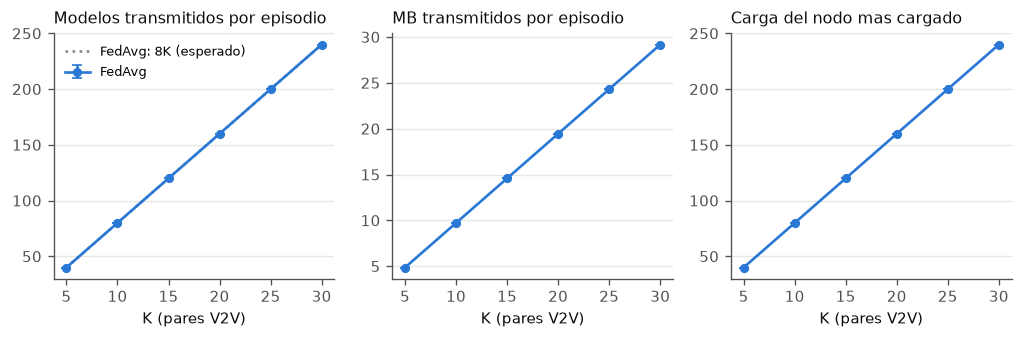

FedAvg transmite lo esperado en todos los K.


In [ ]:
sharing = [
    m
    for m in methods
    if ("comm_models", "mean") in summary
    and summary.loc[m, ("comm_models", "mean")].max() > 0
]
silent = [method_label(m) for m in methods if m not in sharing]
if silent:
    print(f"No transmiten modelos (0 en todos los K): {', '.join(silent)}.")
if sharing:
    fig, axes = plt.subplots(1, 3, figsize=(8.6, 2.9))
    for ax, metric in zip(axes, ["comm_models", "comm_mb", "comm_max_load"]):
        plot_vs_k(ax, summary, metric, sharing)
    axes[0].plot(
        EXPECTED_KS,
        [fedavg_models_per_episode(k) for k in EXPECTED_KS],
        color=REFERENCE,
        linestyle=":",
        label="FedAvg: 8K (esperado)",
    )
    axes[0].legend(fontsize=7.5)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"barrido_comunicacion_{'_'.join(sharing)}.pdf")
    plt.show()
    if "fedavg" in sharing:
        got = summary.loc["fedavg", ("comm_models", "mean")]
        expected = pd.Series({k: fedavg_models_per_episode(k) for k in got.index})
        print(
            "FedAvg transmite lo esperado en todos los K."
            if np.allclose(got, expected)
            else f"FedAvg NO transmite 8K por episodio: {got.to_dict()}"
        )

## Consenso: dispersion de pesos

Distancia euclidiana promedio de los pesos de cada agente al promedio de todos, medida cada 50 slots (en FedAvg, justo antes de agregar). A la izquierda, el valor final vs. K; a la derecha, como evoluciona durante el entrenamiento, una grafica por metodo. En FedAvg debe quedar baja: solo lo que los agentes se separan en 50 slots. `dte.ipynb` la compara con la de modelos que nunca se mezclan.

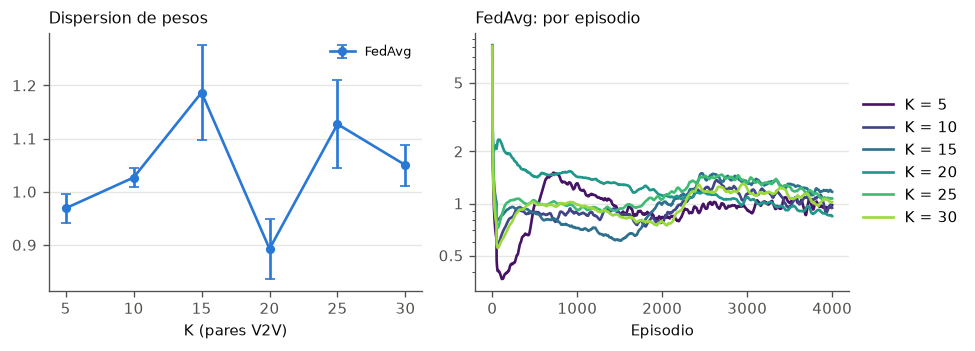

In [ ]:
if learners and "weight_dispersion" in per_episode:
    colors = k_colors(ks)
    fig, axes = plt.subplots(
        1,
        1 + len(learners),
        figsize=(3.4 * (1 + len(learners)) + 1.4, 3.0),
        squeeze=False,
    )
    plot_vs_k(axes[0][0], summary, "weight_dispersion", learners)
    axes[0][0].legend(fontsize=7.5)
    log_y(axes[0][0])
    for ax, method in zip(axes[0][1:], learners):
        data = per_episode[per_episode["method"] == method].sort_values("episode")
        for k in ks:
            run = data[data["k"] == k]
            if run.empty:
                continue
            curve = (
                run.groupby("episode")["weight_dispersion"]
                .mean()
                .rolling(WINDOW, min_periods=1)
                .mean()
            )
            ax.plot(curve.index, curve.values, color=colors[k], label=f"K = {k}")
        log_y(ax)
        ax.set_title(f"{method_label(method)}: por episodio")
        ax.set_xlabel("Episodio")
    axes[0][-1].legend(loc="center left", bbox_to_anchor=(1.0, 0.5))
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"barrido_dispersion_{'_'.join(learners)}.pdf")
    plt.show()

## Perdida de entrenamiento

Perdida promedio del D3QN por episodio (media movil, promedio entre agentes y semillas), una grafica por metodo. Es un chequeo: si diverge en algun K, los demas numeros de ese K no valen.

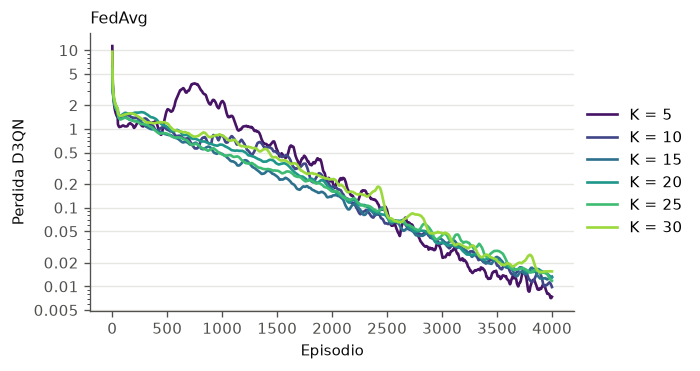

In [ ]:
if learners:
    colors = k_colors(ks)
    fig, axes = plt.subplots(
        1,
        len(learners),
        figsize=(3.8 * len(learners) + 1.4, 3.0),
        squeeze=False,
        sharey=True,
    )
    for ax, method in zip(axes[0], learners):
        data = per_episode[per_episode["method"] == method].sort_values("episode")
        for k in ks:
            run = data[data["k"] == k]
            if run.empty:
                continue
            curve = (
                run.groupby("episode")["train_loss"]
                .mean()
                .rolling(WINDOW, min_periods=1)
                .mean()
            )
            ax.plot(curve.index, curve.values, color=colors[k], label=f"K = {k}")
        log_y(ax)
        ax.set_title(method_label(method))
        ax.set_xlabel("Episodio")
    axes[0][0].set_ylabel(LABELS["train_loss"])
    axes[0][-1].legend(loc="center left", bbox_to_anchor=(1.0, 0.5))
    plt.show()

## Comportamiento vs. K

Que hacen los agentes con los canales y la potencia (el analogo de las Figs. 5 y 7 de Li et al.). La linea gris en *Canales en uso* es el maximo posible, min(K, 15): con mas pares que canales, compartir es inevitable. Greedy siempre transmite a potencia maxima.

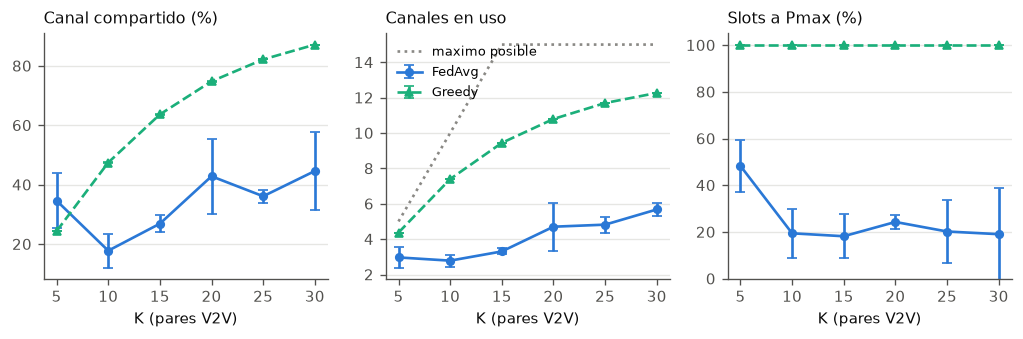

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(8.6, 2.9))
for ax, metric in zip(axes, ["co_channel_rate", "channels_used", "max_power_rate"]):
    plot_vs_k(ax, summary, metric, methods)
axes[1].plot(
    EXPECTED_KS,
    [min(k, 15) for k in EXPECTED_KS],
    color=REFERENCE,
    linestyle=":",
    label="maximo posible",
)
axes[1].legend(fontsize=7.5)
axes[2].set_ylim(0, 105)
fig.tight_layout()
fig.savefig(FIG_DIR / f"barrido_comportamiento_{'_'.join(methods)}.pdf")
plt.show()

## Variabilidad entre episodios

Cada episodio sortea una geometria nueva, asi que la tasa CUE cambia de un episodio a otro aunque el metodo no cambie. La caja va del cuartil 1 al 3 de los episodios del tramo final (todas las semillas juntas) y los bigotes cubren el 5-95 %. Si las cajas de dos metodos se superponen mucho, la diferencia de medias necesita la comparacion pareada por semilla para ser creible.

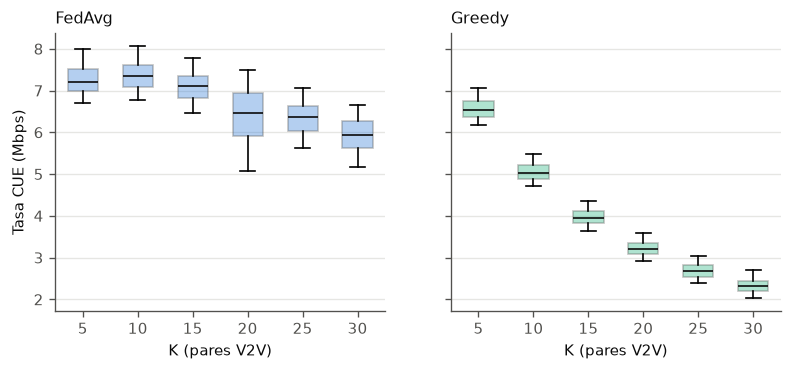

In [ ]:
last_episode = per_episode.groupby(["method", "k", "seed"])["episode"].transform("max")
tail = per_episode[
    per_episode["episode"] > last_episode - np.ceil(FINAL_FRACTION * (last_episode + 1))
]
fig, axes = plt.subplots(
    1, len(methods), figsize=(3.6 * len(methods) + 0.6, 3.0), squeeze=False, sharey=True
)
for ax, method in zip(axes[0], methods):
    data = tail[tail["method"] == method]
    groups = [data.loc[data["k"] == k, "cue_rate_mbps"] for k in ks]
    box = ax.boxplot(
        groups, whis=(5, 95), showfliers=False, patch_artist=True, widths=0.55
    )
    for patch in box["boxes"]:
        patch.set(facecolor=METHODS[method]["color"], alpha=0.35, edgecolor=TEXT_2)
    for median in box["medians"]:
        median.set(color=TEXT)
    ax.set_xticks(range(1, len(ks) + 1), [str(k) for k in ks])
    ax.set_xlabel("K (pares V2V)")
    ax.set_title(method_label(method))
axes[0][0].set_ylabel(LABELS["cue_rate_mbps"])
fig.savefig(FIG_DIR / f"barrido_variabilidad_{'_'.join(methods)}.pdf")
plt.show()

## Tabla resumen

Media ± desviacion entre semillas del tramo final, por metodo y K. «—» marca una metrica que el metodo no tiene.

In [ ]:
TABLE_METRICS = [
    "cue_rate_mbps",
    "reward",
    "outage_rate",
    "v2v_delay_ms",
    "convergence_episode",
    "co_channel_rate",
    "channels_used",
    "mean_power_ratio",
    "max_power_rate",
    "neighbors",
    "isolated_rate",
    "comm_models",
    "comm_mb",
    "comm_max_load",
    "weight_dispersion",
    "train_loss",
]


def cell(mean: float, std: float) -> str:
    if pd.isna(mean):
        return "—"
    return f"{mean:.2f} ± {0.0 if pd.isna(std) else std:.2f}"


for method in methods:
    s = summary.loc[method]
    table = pd.DataFrame(
        {
            LABELS[m]: [
                cell(s.loc[k, (m, "mean")], s.loc[k, (m, "std")]) for k in s.index
            ]
            for m in TABLE_METRICS
            if (m, "mean") in s
        },
        index=pd.Index(s.index, name="K"),
    )
    table["Semillas"] = s[("seeds", "")].to_list()
    print(method_label(method))
    display(table)

FedAvg


,Tasa CUE (Mbps),Recompensa por episodio,Outage (%),Delay V2V (ms),Episodios hasta converger,Canal compartido (%),Canales en uso,Potencia media / Pmax,Slots a Pmax (%),Vecinos a 300 m o menos,Pares sin vecinos (%),Modelos transmitidos por episodio,MB transmitidos por episodio,Carga del nodo mas cargado,Dispersion de pesos,Perdida D3QN,Semillas
K,,,,,,,,,,,,,,,,,
5,7.27 ± 0.27,5804.30 ± 294.08,52.63 ± 9.81,4.47 ± 6.00,3935.00 ± 0.00,34.62 ± 9.20,2.97 ± 0.57,0.63 ± 0.14,48.28 ± 11.09,1.07 ± 0.03,29.65 ± 1.23,40.00 ± 0.00,4.86 ± 0.00,40.00 ± 0.00,0.97 ± 0.03,0.01 ± 0.00,3
10,7.37 ± 0.18,3406.74 ± 277.07,78.82 ± 3.36,24.67 ± 6.56,3995.00 ± 0.00,17.77 ± 5.66,2.78 ± 0.34,0.30 ± 0.09,19.42 ± 10.41,2.42 ± 0.01,7.68 ± 0.44,80.00 ± 0.00,9.73 ± 0.00,80.00 ± 0.00,1.03 ± 0.02,0.01 ± 0.00,3
15,7.10 ± 0.07,1748.64 ± 72.09,84.06 ± 0.79,21.05 ± 1.67,—,26.87 ± 2.88,3.30 ± 0.17,0.31 ± 0.03,18.17 ± 9.39,3.79 ± 0.04,2.38 ± 0.21,120.00 ± 0.00,14.59 ± 0.00,120.00 ± 0.00,1.19 ± 0.09,0.01 ± 0.00,3
20,6.40 ± 0.66,329.50 ± 215.68,82.33 ± 5.55,12.37 ± 7.16,—,42.82 ± 12.59,4.70 ± 1.36,0.40 ± 0.05,24.28 ± 3.04,5.15 ± 0.01,0.84 ± 0.16,160.00 ± 0.00,19.45 ± 0.00,160.00 ± 0.00,0.89 ± 0.06,0.02 ± 0.00,3
25,6.34 ± 0.23,-1628.12 ± 294.87,85.85 ± 2.25,19.29 ± 5.01,—,36.10 ± 2.19,4.82 ± 0.45,0.33 ± 0.07,20.19 ± 13.33,6.47 ± 0.06,0.24 ± 0.06,200.00 ± 0.00,24.32 ± 0.00,200.00 ± 0.00,1.13 ± 0.08,0.02 ± 0.00,3
30,5.94 ± 0.19,-3456.02 ± 258.40,86.79 ± 0.87,17.52 ± 6.32,—,44.60 ± 13.04,5.68 ± 0.37,0.37 ± 0.17,19.05 ± 19.57,7.83 ± 0.06,0.09 ± 0.02,240.00 ± 0.00,29.18 ± 0.00,240.00 ± 0.00,1.05 ± 0.04,0.02 ± 0.00,3


Greedy


,Tasa CUE (Mbps),Recompensa por episodio,Outage (%),Delay V2V (ms),Episodios hasta converger,Canal compartido (%),Canales en uso,Potencia media / Pmax,Slots a Pmax (%),Vecinos a 300 m o menos,Pares sin vecinos (%),Modelos transmitidos por episodio,MB transmitidos por episodio,Carga del nodo mas cargado,Dispersion de pesos,Perdida D3QN,Semillas
K,,,,,,,,,,,,,,,,,
5,6.57 ± 0.01,7028.96 ± 67.01,25.48 ± 0.15,0.02 ± 0.00,—,24.36 ± 0.11,4.37 ± 0.00,1.00 ± 0.00,100.00 ± 0.00,1.07 ± 0.03,29.65 ± 1.23,0.00 ± 0.00,0.00 ± 0.00,0.00 ± 0.00,—,—,3
10,5.05 ± 0.01,5623.62 ± 53.60,34.28 ± 0.23,0.03 ± 0.00,—,47.43 ± 0.14,7.40 ± 0.01,1.00 ± 0.00,100.00 ± 0.00,2.42 ± 0.01,7.68 ± 0.44,0.00 ± 0.00,0.00 ± 0.00,0.00 ± 0.00,—,—,3
15,3.98 ± 0.01,3436.83 ± 80.19,42.66 ± 0.23,0.03 ± 0.00,—,63.65 ± 0.04,9.44 ± 0.00,1.00 ± 0.00,100.00 ± 0.00,3.79 ± 0.04,2.38 ± 0.21,0.00 ± 0.00,0.00 ± 0.00,0.00 ± 0.00,—,—,3
20,3.22 ± 0.00,895.20 ± 64.59,50.53 ± 0.23,0.04 ± 0.00,—,74.79 ± 0.07,10.79 ± 0.01,1.00 ± 0.00,100.00 ± 0.00,5.15 ± 0.01,0.84 ± 0.16,0.00 ± 0.00,0.00 ± 0.00,0.00 ± 0.00,—,—,3
25,2.69 ± 0.01,-1730.58 ± 14.32,57.39 ± 0.35,0.05 ± 0.00,—,82.16 ± 0.01,11.70 ± 0.01,1.00 ± 0.00,100.00 ± 0.00,6.47 ± 0.06,0.24 ± 0.06,0.00 ± 0.00,0.00 ± 0.00,0.00 ± 0.00,—,—,3
30,2.34 ± 0.01,-4371.67 ± 103.05,63.65 ± 0.34,0.07 ± 0.00,—,87.13 ± 0.02,12.26 ± 0.02,1.00 ± 0.00,100.00 ± 0.00,7.83 ± 0.06,0.09 ± 0.02,0.00 ± 0.00,0.00 ± 0.00,0.00 ± 0.00,—,—,3


## Tiempo de computo

Del JSON que deja cada corrida junto a su CSV. Sirve para la tabla de configuracion experimental y para saber cuanto pedirle a Slurm en las siguientes corridas.

In [ ]:
meta = load_metadata(RUNS_ROOT, methods=METHODS_TO_SHOW)
if meta.empty:
    print("No hay JSON de metadatos junto a los CSV.")
else:
    meta["horas"] = meta["wall_time_s"] / 3600
    display(
        meta.pivot_table(index=["method", "k"], columns="seed", values="horas")
        .round(2)
        .rename(index=method_label, level="method")
    )
    print("Maquinas:", ", ".join(sorted(meta["host"].dropna().unique())))
    if "gpu" in meta:
        print("GPU:", ", ".join(sorted(meta["gpu"].dropna().unique())))

seed           0      1      2
method k                      
FedAvg 5    4.54   4.55   4.55
       10   9.04   9.05   9.05
       15  13.61  13.63  13.63
       20  18.75  18.73  18.75
       25  22.76  22.77  22.77
       30  27.26  27.26  27.23
Greedy 5    0.06   0.07   0.07
       10   0.09   0.09   0.10
       15   0.12   0.12   0.12
       20   0.29   0.14   0.14
       25   0.18   0.18   0.18
       30   0.21   0.20   0.21

Maquinas: nodea-6, nodei-10, nodei-3, nodei-6, nodei-7, nodei-8, nodei-gpu-1
GPU: Quadro RTX 6000


## Chequeos

Lo que tiene que cumplirse para que la replica sea creible: la tasa CUE baja al crecer K, FedAvg le gana a Greedy en todos los K y en todas las semillas, y los episodios hasta converger no bajan al crecer K (lo que afirma el paper).

In [ ]:
for method in methods:
    rate = summary.loc[method, ("cue_rate_mbps", "mean")]
    falls = bool((rate.diff().dropna() < 0).all())
    print(
        f"{method_label(method)}: la tasa CUE {'baja' if falls else 'NO baja'} en cada paso de K ({', '.join(f'{v:.2f}' for v in rate)} Mbps)."
    )
    if method in LI_FIG3_MBPS and {min(ks), max(ks)} <= set(rate.index):
        ours = rate[max(ks)] / rate[min(ks)] - 1
        ref = LI_FIG3_MBPS[method]
        theirs = ref[max(ks)] / ref[min(ks)] - 1
        print(
            f"  De K = {min(ks)} a K = {max(ks)}: {100 * ours:+.0f} % aqui frente a {100 * theirs:+.0f} % en Li et al."
        )

FedAvg: la tasa CUE NO baja en cada paso de K (7.27, 7.37, 7.10, 6.40, 6.34, 5.94 Mbps).
  De K = 5 a K = 30: -18 % aqui frente a -41 % en Li et al.
Greedy: la tasa CUE baja en cada paso de K (6.57, 5.05, 3.98, 3.22, 2.69, 2.34 Mbps).
  De K = 5 a K = 30: -64 % aqui frente a -70 % en Li et al.


In [ ]:
A, B = "fedavg", "greedy"
if {A, B} <= set(methods):
    reward = final["reward"].unstack("method")[[A, B]].dropna()
    beats = (reward[A] > reward[B]).groupby(level="k").all()
    lost = [k for k, ok in beats.items() if not ok]
    if lost:
        print(
            f"{method_label(A)} NO le gana a {method_label(B)} en recompensa en todas las semillas con K = {lost}."
        )
    else:
        print(
            f"{method_label(A)} le gana a {method_label(B)} en recompensa en todas las semillas (K = {list(beats.index)})."
        )

FedAvg NO le gana a Greedy en recompensa en todas las semillas con K = [5, 10, 15, 20, 25].


In [ ]:
for method in learners:
    if "convergence_episode" not in final:
        break
    conv = summary.loc[method, ("convergence_episode", "mean")].dropna()
    if conv.empty:
        print(
            f"Ninguna corrida de {method_label(method)} se estabiliza todavia: no se puede revisar la convergencia vs. K."
        )
    else:
        grows = bool((conv.diff().dropna() >= 0).all())
        print(
            f"Episodios hasta converger de {method_label(method)}: {', '.join(f'K={k}: {v:.0f}' for k, v in conv.items())} ({'no bajan' if grows else 'NO crecen de forma monotona'} con K)."
        )

Episodios hasta converger de FedAvg: K=5: 3935, K=10: 3995 (no bajan con K).
